In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from scipy.stats import norm
np.random.seed=17

In [5]:
run=6
flip=10000
coin_flip=np.random.randint(0,2,size=(run,flip))

In [6]:
cumulative=np.cumsum(coin_flip,axis=1)
total_flip=np.arange(1,flip+1)
head_percent=cumulative/total_flip

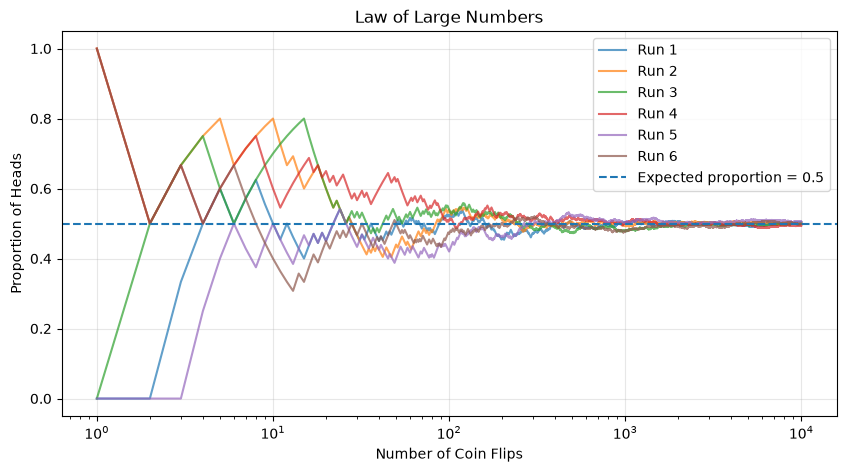

In [16]:
plt.figure(figsize=(10, 5))

for i in range(run):
    plt.plot(total_flip, head_percent[i],
             alpha=0.7, label=f'Run {i+1}')

plt.axhline(0.5, linestyle='--',
            label='Expected proportion = 0.5')

plt.xscale('log')
plt.title('Law of Large Numbers')
plt.xlabel('Number of Coin Flips')
plt.ylabel('Proportion of Heads')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [8]:
walker=2000
step=1000
move=np.random.choice([-1,1],size=(walker,step))
position=np.cumsum(move,axis=1)


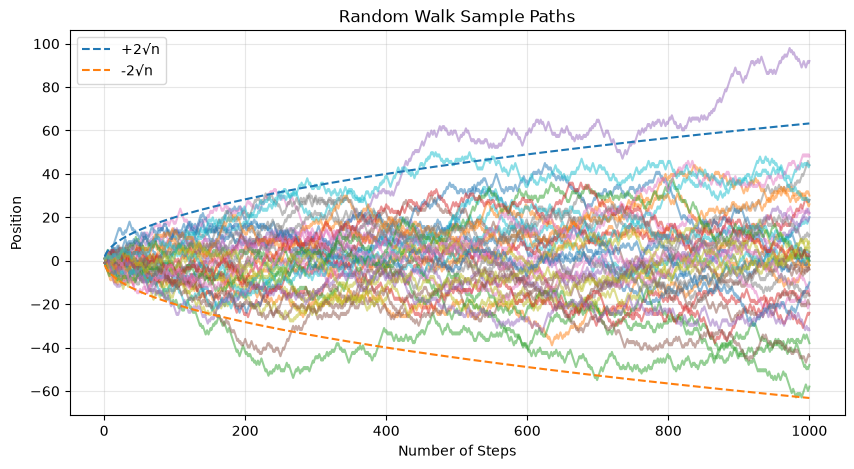

In [9]:
plt.figure(figsize=(10, 5))

for i in range(40):
    plt.plot(np.arange(1, step + 1),
             position[i],
             alpha=0.5)

plt.plot(np.arange(1, step + 1),
         2 * np.sqrt(np.arange(1, step + 1)),
         linestyle='--', label='+2√n')

plt.plot(np.arange(1, step + 1),
         -2 * np.sqrt(np.arange(1, step + 1)),
         linestyle='--', label='-2√n')

plt.title('Random Walk Sample Paths')
plt.xlabel('Number of Steps')
plt.ylabel('Position')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

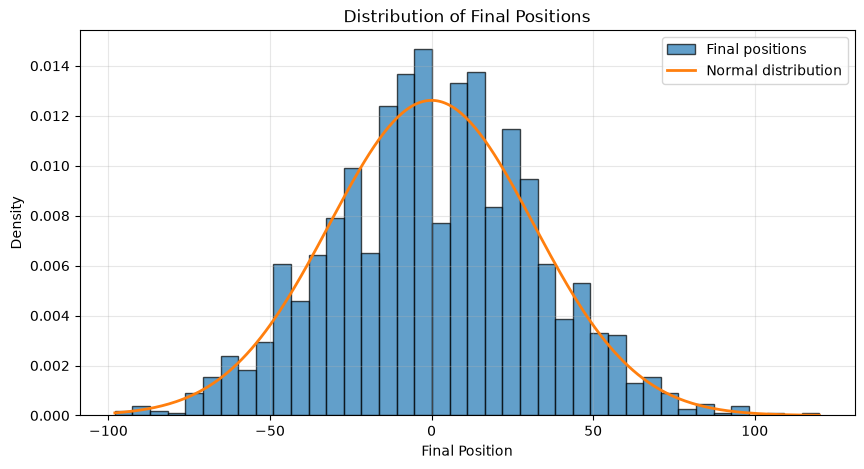

In [12]:
plt.figure(figsize=(10, 5))

final_positions = position[:, -1]

plt.hist(
    final_positions,
    bins=40,
    density=True,
    alpha=0.7,
    edgecolor='black',
    label='Final positions'
)

x = np.linspace(
    final_positions.min(),
    final_positions.max(),
    300
)

plt.plot(
    x,
    norm.pdf(x, loc=0, scale=np.sqrt(step)),
    label='Normal distribution',
    linewidth=2
)

plt.title('Distribution of Final Positions')
plt.xlabel('Final Position')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
spread = np.std(position, axis=0)
expected_spread = np.sqrt(np.arange(1, step + 1))

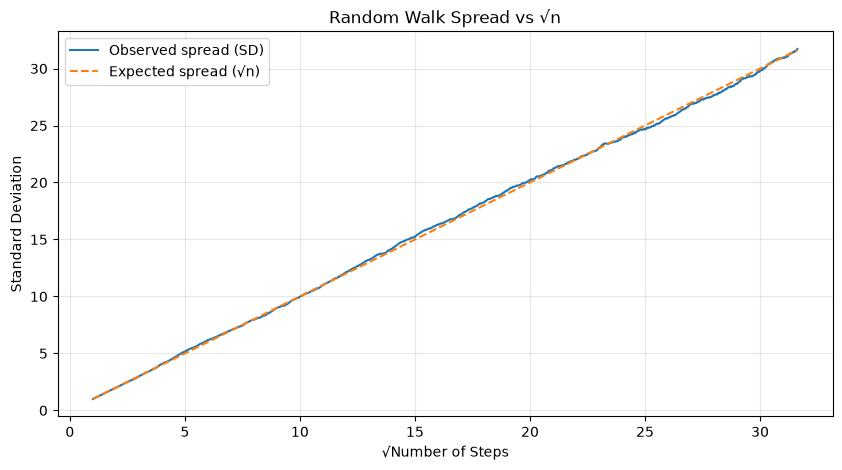

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.sqrt(np.arange(1, step + 1)),
    spread,
    label='Observed spread (SD)'
)

plt.plot(
    np.sqrt(np.arange(1, step + 1)),
    expected_spread,
    linestyle='--',
    label='Expected spread (√n)'
)

plt.title('Random Walk Spread vs √n')
plt.xlabel('√Number of Steps')
plt.ylabel('Standard Deviation')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()